# Train iBeamNet: sigmoid/Gaussian posterior
Version 4 predicts per-cell P, Y and E. Train with exact spike-and-slab NLL, including the Gaussian constant. The point estimate is P*Y. Reconstruction is disabled by default and has weight zero. Existing entmax checkpoints remain separate.


In [1]:
from pathlib import Path
import sys
import re
import os
import math
import json
import copy
try:
    import tomllib
except ImportError:
    import tomli as tomllib

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm

ROOT = Path.cwd().resolve()
if ROOT.name == "examples":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
EXAMPLES = ROOT / "examples"
import ibeamlab as ibl
from ibeamlab import iBeamNet, iBeamNetLoss
from ibeamlab._native import native

c:\Users\local_admin\.conda\envs\DL\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Dataset and measurement contract

Choose one dataset collection generated with the same fixed experimental setup
and reference methods. Mixing calibrations, exposures, geometries, or pileup
conditions does not produce a spectra-only inverse model with a well-defined
reference setup. The loader checks stored setup, sample templates, method
references, and parameter targets against this configuration. Supply only
compatible datasets; channel padding below extends the same reference grid.

In [2]:
DATASET_ROOT = EXAMPLES / "datasets/iba_multilayer_13el"
CONFIG_PATH = EXAMPLES / "multilayer-generation.toml"
Nmaxlayers = 8  # Include only datasets with 1..Nmaxlayers layers
MAX_LAYERS = Nmaxlayers

configuration = ibl.load_generation_configuration(CONFIG_PATH)
if configuration.variations:
    raise ValueError("iBeamNet requires fixed beam/detector settings; choose a config without setup variations")
if not isinstance(Nmaxlayers,int) or isinstance(Nmaxlayers,bool) or not 1 <= Nmaxlayers <= configuration.maximum_layers:
    raise ValueError("Nmaxlayers must be a positive integer within the configuration maximum")
study = configuration.study(MAX_LAYERS)
ELEMENTS = tuple(configuration.elements)
LABELS = tuple(d.label for d in study.experiment.detectors)
LAYER_DATASETS = {}
for path in sorted(DATASET_ROOT.rglob("layers_*")):
    match = re.fullmatch(r"layers_(\d+)", path.name)
    if path.is_dir() and match and 1 <= int(match.group(1)) <= Nmaxlayers:
        LAYER_DATASETS.setdefault(int(match.group(1)), []).append(path)
if not LAYER_DATASETS:
    raise FileNotFoundError(f"No layers_XX datasets under {DATASET_ROOT}")
print("Detector order:", LABELS)
print("Element order:", ELEMENTS)
print("Maximum layers:", MAX_LAYERS)

Detector order: ('RBS',)
Element order: ('Li', 'Ni', 'Mn', 'Co', 'O', 'C', 'F', 'P', 'Cu', 'Al', 'Si', 'Na', 'Fe')
Maximum layers: 8


## 2. Load spectra and construct areal-density targets

Each target entry is `thickness[layer] * concentration[layer, element]` in
`1e15 atoms/cm2`. Deeper layers absent from a dataset are exact zero rows.
Concentrations are validated, not silently renormalized. Raw spectra are
concatenated in detector order; CNN branches keep detector boundaries separate.
This eager loader holds the selected datasets in memory, as in the LRN notebook.

In [3]:
def template_table(text):
    value = tomllib.loads(text)
    value.pop("format", None)
    value.pop("format_version", None)
    return value

def load_case(dataset_path, layer_count):
    dataset = ibl.open_dataset(dataset_path)
    if not dataset.metadata.complete or not len(dataset):
        raise ValueError(f"Incomplete or empty dataset: {dataset_path}")
    case = configuration.study(layer_count)
    config = case._config()
    provenance = tomllib.loads(dataset._reader.metadata.generation_config_toml)
    expected_setup = template_table(native.sample.setup_to_toml(config.setup))
    expected_sample = template_table(native.sample.sample_to_toml(config.sample))
    if provenance.get("setup") != expected_setup or provenance.get("sample") != expected_sample:
        raise ValueError(f"Dataset template/setup differs from CONFIG_PATH: {dataset_path}")
    expected_methods = [{"label": m.label, "iba_method": m.iba_method,
                         "reference_file": Path(m.reference_file).as_posix()} for m in config.methods]
    if provenance.get("methods") != expected_methods:
        raise ValueError(f"Dataset method/reference differs from CONFIG_PATH: {dataset_path}")
    names = tuple(dataset.metadata.parameter_names)
    if len(set(names)) != len(names) or set(names) != set(case.parameter_names):
        raise ValueError(f"Parameter names do not match the case study: {dataset_path}")
    stored_targets = {p["name"]: p["target"] for p in provenance.get("parameters", [])}
    for p in case.parameters:
        expected_target = ({"type": "layer_thickness", "layer": p.layer} if p.kind == "layer_thickness"
                           else {"type": "species_concentration", "layer": p.layer, "element": p.element})
        if stored_targets.get(p.name) != expected_target:
            raise ValueError(f"Parameter target differs for {p.name}: {dataset_path}")
    rows = np.asarray(dataset.parameters, dtype=np.float32)
    columns = {name: i for i, name in enumerate(names)}
    densities = np.zeros((len(rows), MAX_LAYERS, len(ELEMENTS)), np.float32)
    for layer_index in range(layer_count):
        layer = case.experiment.sample.layers[layer_index]
        thickness = np.full(len(rows), layer.thickness, np.float32)
        fractions = np.tile([next(s.concentration for s in layer.species if s.element == element)
                             for element in ELEMENTS], (len(rows), 1)).astype(np.float32)
        for p in case.parameters:
            if p.layer != layer_index:
                continue
            if p.kind == "layer_thickness":
                thickness = rows[:, columns[p.name]]
            elif p.kind == "concentration":
                fractions[:, ELEMENTS.index(p.element)] = rows[:, columns[p.name]]
        if np.any(thickness < 0) or np.any(fractions < 0) or not np.allclose(fractions.sum(1), 1, atol=1e-6, rtol=0):
            raise ValueError(f"Invalid thickness/composition: {dataset_path}")
        densities[:, layer_index] = thickness[:, None] * fractions
    spectra = {label: np.asarray(dataset.spectra(label), dtype=np.float32) for label in LABELS}
    if any(not np.isfinite(x).all() or np.any(x < 0) for x in spectra.values()) or not np.isfinite(densities).all():
        raise ValueError(f"Nonfinite or negative training data: {dataset_path}")
    return spectra, densities

loaded = []
SPECTRUM_LENGTHS = {label: 0 for label in LABELS}
for layer_count, paths in sorted(LAYER_DATASETS.items()):
    for path in paths:
        spectra, densities = load_case(path, layer_count)
        for label in LABELS:
            SPECTRUM_LENGTHS[label] = max(SPECTRUM_LENGTHS[label], spectra[label].shape[1])
        loaded.append((spectra, densities))
        print(f"Loaded {path}: {len(densities):,} samples, {layer_count} layers")
x_parts, a_parts = [], []
for spectra, densities in loaded:
    x_parts.append(np.concatenate([
        np.pad(spectra[label], ((0, 0), (0, SPECTRUM_LENGTHS[label] - spectra[label].shape[1])))
        for label in LABELS], axis=1))
    a_parts.append(densities)
x_raw = np.concatenate(x_parts)
a_raw = np.concatenate(a_parts)
del loaded, x_parts, a_parts
print("Raw spectra:", x_raw.shape, "EDP:", a_raw.shape)

Loaded D:\ibeamlab\examples\datasets\iba_multilayer_13el\layers_01: 430,000 samples, 1 layers
Loaded D:\ibeamlab\examples\datasets\iba_multilayer_13el\layers_02: 300,000 samples, 2 layers
Loaded D:\ibeamlab\examples\datasets\iba_multilayer_13el\layers_03: 300,000 samples, 3 layers
Loaded D:\ibeamlab\examples\datasets\iba_multilayer_13el\layers_04: 300,000 samples, 4 layers
Loaded D:\ibeamlab\examples\datasets\iba_multilayer_13el\layers_05: 300,000 samples, 5 layers
Loaded D:\ibeamlab\examples\datasets\iba_multilayer_13el\layers_06: 300,000 samples, 6 layers
Loaded D:\ibeamlab\examples\datasets\iba_multilayer_13el\layers_07: 300,000 samples, 7 layers
Loaded D:\ibeamlab\examples\datasets\iba_multilayer_13el\layers_08: 300,000 samples, 8 layers
Raw spectra: (2530000, 2998) EDP: (2530000, 8, 13)


## 3. Data preprocessing
Run once after loading: reproducible splits, bounded-memory training normalization, common AD scaling, fixed Poisson inputs, and fixed epoch evaluation subsets. Rerunning training reuses these prepared arrays.


In [4]:
# Data preprocessing settings; optimizer/model/loss settings remain in the training cell.
SEED = 7
AD_RESCALE_FACTOR = 1e4  # physical AD / this common factor = training AD
TARGET_SCALE = 1.0/AD_RESCALE_FACTOR
POISSON_NOISE = True
EVALUATION_SAMPLES = 20_000
if not math.isfinite(AD_RESCALE_FACTOR) or AD_RESCALE_FACTOR<=0:
    raise ValueError('AD_RESCALE_FACTOR must be positive and finite')
if len(x_raw) < 10:
    raise ValueError("At least 10 samples are needed")
order = np.random.default_rng(SEED).permutation(len(x_raw))
n_val = min(max(1, int(0.1 * len(order))), 20_000)
n_test = min(max(1, int(0.1 * len(order))), 10_000)
train_indices = order[:len(order) - n_val - n_test]
val_indices = order[len(order) - n_val - n_test:len(order) - n_test]
test_indices = order[-n_test:]
log_train = np.log1p(x_raw[train_indices])
input_mean = log_train.mean(axis=0, dtype=np.float64).astype(np.float32)
input_std = np.maximum(log_train.std(axis=0, dtype=np.float64), 1e-3).astype(np.float32)
del log_train
if not np.isfinite(TARGET_SCALE) or TARGET_SCALE <= 0:
    raise ValueError("TARGET_SCALE must be positive")
x_train, x_val, x_test = (x_raw[i] for i in (train_indices, val_indices, test_indices))
a_train, a_val, a_test = (a_raw[i] * TARGET_SCALE for i in (train_indices, val_indices, test_indices))

# Fixed raw-count draws keep validation/checkpoint comparisons and test/native
# parity reproducible. Training counts remain clean until each batch is drawn.
def fixed_poisson_counts(expected_counts, seed):
    generator = torch.Generator(device="cpu").manual_seed(seed)
    noisy = np.empty_like(expected_counts)
    for start in range(0, len(expected_counts), 512):
        stop = min(start + 512, len(expected_counts))
        noisy[start:stop] = torch.poisson(
            torch.from_numpy(expected_counts[start:stop]), generator=generator).numpy()
    return noisy

x_val_clean,x_test_clean=x_val,x_test
if POISSON_NOISE:
    x_val = fixed_poisson_counts(x_val, SEED + 1)
    x_test = fixed_poisson_counts(x_test, SEED + 2)



def fixed_subset(count,seed):
    return np.arange(count) if count<=EVALUATION_SAMPLES else np.sort(np.random.default_rng(seed).choice(count,EVALUATION_SAMPLES,replace=False))
train_eval_indices = fixed_subset(len(x_train),SEED+101)
val_eval_indices = fixed_subset(len(x_val),SEED+102)
x_train_eval = fixed_poisson_counts(x_train[train_eval_indices],SEED+103) if POISSON_NOISE else x_train[train_eval_indices]

prepared_max_layers=MAX_LAYERS
print(f'Prepared train/validation/test: {len(x_train):,} / {len(x_val):,} / {len(x_test):,}')
print(f'Fixed epoch evaluation: {len(train_eval_indices):,} train / {len(val_eval_indices):,} validation')


Prepared train/validation/test: 2,500,000 / 20,000 / 10,000
Fixed epoch evaluation: 20,000 train / 20,000 validation


## 4. Training settings and protected training
All optimization settings live here. Presence uses stable BCEWithLogits; Gaussian NLL applies only where true AD is positive. RESUME=True restores matching checkpoints, or starts fresh when none exist.


In [19]:
# All training settings are in this cell.
RESUME = True
VERSION = 4
MODEL_OPTIONS = dict(cnn_channels=(32,64,128,128), kernel_size=7,
    attention_size=128, attention_heads=4, attention_blocks=2, dropout=0.0,
    initial_density=0.01, presence_mapping='sigmoid', minimum_std=1e-5)
OUTPUT_DIR = EXAMPLES/f'artifacts/ibeamnet_v4_gaussian_nll_13el_{MAX_LAYERS}layer'
GAUSSIAN_DEPTH_ALPHA = 2.0  # Gaussian depth decay; 0 gives unweighted NLL
CPU_THREADS = 8
use_reconstruction_loss =  True
RECONSTRUCTION_WEIGHT = 1000
LRN_AD_CHECKPOINT = EXAMPLES/'artifacts/lrn_ad_rbs_13el_8layer/continuation/lrn_ad_best.pt'
BATCH_SIZE = 512
VALIDATION_BATCH_SIZE = 2048
DATALOADER_WORKERS = 0
WEIGHT_DECAY = 1e-4
MAX_GRAD_NORM = 5.0
TRAINING_SCHEDULE = [
    {'learning_rate':5e-4, 'epochs':90},
    {'learning_rate':1e-4, 'epochs': 30},
    {'learning_rate':5e-5, 'epochs':10},
    #{'learning_rate':1e-5, 'epochs':10},
]
# Version 1 options instead: dict(cnn_channels=(32,64,128,128),kernel_size=7,
# compression_channels=16,head_hidden_sizes=(128,),decoder_hidden_size=256,
# decoder_layers=2,bidirectional=True,layer_embedding_size=32,dropout=.1,initial_density=0.01, presence_mapping='sigmoid', minimum_std=1e-5)

import importlib
import time
import ibeamlab.ibeamnet as ibeamnet_module
importlib.reload(ibeamnet_module)
iBeamNet, iBeamNetLoss = ibeamnet_module.iBeamNet, ibeamnet_module.iBeamNetLoss
torch.set_num_threads(CPU_THREADS)
if not isinstance(RESUME,bool): raise ValueError('RESUME must be True or False')
if min(BATCH_SIZE,VALIDATION_BATCH_SIZE,EVALUATION_SAMPLES)<1 or DATALOADER_WORKERS<0:
    raise ValueError('Invalid batch/worker/evaluation settings')
if not math.isfinite(WEIGHT_DECAY) or WEIGHT_DECAY<0 or not math.isfinite(MAX_GRAD_NORM) or MAX_GRAD_NORM<=0:
    raise ValueError('Invalid optimizer settings')
if not TRAINING_SCHEDULE or any(not isinstance(s['epochs'],int) or s['epochs']<1 or not math.isfinite(s['learning_rate']) or s['learning_rate']<=0 for s in TRAINING_SCHEDULE):
    raise ValueError('Invalid training schedule')
if 'prepared_max_layers' not in globals() or prepared_max_layers!=MAX_LAYERS:
    raise ValueError('Run the data preprocessing cell for the selected Nmaxlayers before training')

torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = iBeamNet(study,SPECTRUM_LENGTHS,version=VERSION,model_options=MODEL_OPTIONS,
    elements=ELEMENTS,input_mean=input_mean,input_std=input_std).to(device)
loss_function = iBeamNetLoss(include_constant=True, gaussian_depth_alpha=GAUSSIAN_DEPTH_ALPHA)
lrn = None
lrn_checkpoint = None
if not isinstance(use_reconstruction_loss,bool) or not math.isfinite(RECONSTRUCTION_WEIGHT) or RECONSTRUCTION_WEIGHT<0:
    raise ValueError('Invalid reconstruction settings')
if use_reconstruction_loss and RECONSTRUCTION_WEIGHT>0:
    from ibeamlab.lrn_ad import LRN_AD
    import hashlib
    lrn_checkpoint = torch.load(LRN_AD_CHECKPOINT,map_location='cpu',weights_only=False)
    method = lrn_checkpoint['method']
    if len(LABELS)!=1 or method!=LABELS[0] or tuple(lrn_checkpoint['elements'])!=ELEMENTS or lrn_checkpoint['max_layers']<MAX_LAYERS:
        raise ValueError('Frozen LRN_AD detector/elements differ, or it supports fewer layers than Nmaxlayers')
    DECODER_MAX_LAYERS=int(lrn_checkpoint['max_layers'])
    decoder_study=configuration.study(DECODER_MAX_LAYERS)
    if lrn_checkpoint.get('layer_representation')!='areal_density' or tuple(lrn_checkpoint['input_parameter_names'])!=tuple(decoder_study.parameter_names):
        raise ValueError('Frozen LRN_AD representation/parameter order differs')
    if lrn_checkpoint['model_state_dict']['output_scale'].numel()!=SPECTRUM_LENGTHS[method]:
        raise ValueError('Frozen LRN_AD channel width differs')
    LRN_AD_INPUT_FACTOR=float(lrn_checkpoint['ad_input_factor'])
    LRN_AD_OUTPUT_SCALE=float(lrn_checkpoint['output_scale'])
    if min(LRN_AD_INPUT_FACTOR,LRN_AD_OUTPUT_SCALE)<=0 or not np.isfinite([LRN_AD_INPUT_FACTOR,LRN_AD_OUTPUT_SCALE]).all():
        raise ValueError('Invalid decoder scales')
    lrn = LRN_AD(decoder_study,{method:SPECTRUM_LENGTHS[method]},elements=ELEMENTS,
        ad_input_factor=LRN_AD_INPUT_FACTOR,**lrn_checkpoint['architecture']).to(device)
    lrn.load_state_dict(lrn_checkpoint['model_state_dict']);lrn.eval().requires_grad_(False)
    reconstruction_weights=torch.ones(SPECTRUM_LENGTHS[method],device=device)
    reconstruction_weights[1100:]=5.0
    reconstruction_weights/=reconstruction_weights.mean()

def loss_components(prediction,targets,clean_counts):
    zero=targets.new_zeros(())
    nll=loss_function(prediction,targets)
    reconstruction=zero
    if use_reconstruction_loss and RECONSTRUCTION_WEIGHT>0:
        decoder_ad=torch.nn.functional.pad(prediction.mean,(0,0,0,DECODER_MAX_LAYERS-MAX_LAYERS))
        scaled_ad=decoder_ad.flatten(1)*(LRN_AD_INPUT_FACTOR/TARGET_SCALE)
        predicted_spectrum=lrn(scaled_ad)
        target_spectrum=clean_counts*LRN_AD_OUTPUT_SCALE
        reconstruction=(reconstruction_weights*(predicted_spectrum-target_spectrum).square()/(target_spectrum+1)).mean()
    total=nll+RECONSTRUCTION_WEIGHT*reconstruction
    return total,nll,reconstruction

OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
weights_path, resume_path = OUTPUT_DIR/'ibeamnet_best.pt', OUTPUT_DIR/'ibeamnet_resume.pt'
if not RESUME and (weights_path.exists() or resume_path.exists()):
    raise FileExistsError('RESUME=False starts from scratch; choose a fresh OUTPUT_DIR to preserve saved checkpoints')
epoch_schedule = [(i,float(s['learning_rate'])) for i,s in enumerate(TRAINING_SCHEDULE,1) for _ in range(s['epochs'])]
TOTAL_EPOCHS = len(epoch_schedule)
signature = dict(objective='spike_slab_gaussian_nll_with_constant',
    gaussian_depth_alpha=GAUSSIAN_DEPTH_ALPHA,
    use_reconstruction_loss=use_reconstruction_loss,reconstruction_weight=RECONSTRUCTION_WEIGHT,
    decoder_sha256=hashlib.sha256(LRN_AD_CHECKPOINT.read_bytes()).hexdigest() if use_reconstruction_loss and RECONSTRUCTION_WEIGHT>0 else None,
    reconstruction_definition='lrn_ad_scaled_tail_chi2_mean',version=VERSION,model_options=model.model_options,max_layers=MAX_LAYERS,
    elements=list(ELEMENTS),labels=list(LABELS),spectrum_lengths=SPECTRUM_LENGTHS,target_scale=TARGET_SCALE,
    input_noise=dict(poisson=POISSON_NOISE,validation_seed=SEED+1,test_seed=SEED+2),
    config_text=CONFIG_PATH.read_text(),seed=SEED,evaluation_samples=EVALUATION_SAMPLES,
    dataset_manifest=[dict(path=str(path.resolve()),files=[(f.name,f.stat().st_size,f.stat().st_mtime_ns)
        for f in sorted(path.iterdir()) if f.is_file()]) for paths in LAYER_DATASETS.values() for path in paths])

@torch.inference_mode()
def evaluate_metrics(inputs,targets,clean_counts):
    model.eval()
    if lrn is not None:lrn.eval()
    sums=np.zeros(3,np.float64)
    for start in range(0,len(inputs),VALIDATION_BATCH_SIZE):
        stop=start+VALIDATION_BATCH_SIZE
        x=torch.from_numpy(inputs[start:stop]).to(device)
        a=torch.from_numpy(targets[start:stop]).to(device)
        clean=torch.from_numpy(clean_counts[start:stop]).to(device)
        components=loss_components(model(x),a,clean)
        sums+=np.array([float(v) for v in components])*len(x)
    return dict(zip(('total','nll','reconstruction'),(sums/len(inputs)).tolist()))

def evaluate_loss(inputs,targets,clean_counts):
    return evaluate_metrics(inputs,targets,clean_counts)['total']

def evaluate_validation():
    return evaluate_loss(x_val[val_eval_indices],a_val[val_eval_indices],x_val_clean[val_eval_indices])

@torch.inference_mode()
def evaluate_truth_reconstruction():
    """Frozen-surrogate error with true validation AD, independent of iBeamNet."""
    if not use_reconstruction_loss or RECONSTRUCTION_WEIGHT<=0:
        return None
    lrn.eval()
    total,seen=0.0,0
    for start in range(0,len(val_eval_indices),VALIDATION_BATCH_SIZE):
        indices=val_eval_indices[start:start+VALIDATION_BATCH_SIZE]
        truth=torch.from_numpy(a_val[indices]).to(device)
        clean=torch.from_numpy(x_val_clean[indices]).to(device)
        decoder_ad=torch.nn.functional.pad(truth,(0,0,0,DECODER_MAX_LAYERS-MAX_LAYERS))
        predicted_spectrum=lrn(decoder_ad.flatten(1)*(LRN_AD_INPUT_FACTOR/TARGET_SCALE))
        target_spectrum=clean*LRN_AD_OUTPUT_SCALE
        error=(reconstruction_weights*(predicted_spectrum-target_spectrum).square()/(target_spectrum+1)).mean()
        total+=float(error)*len(indices)
        seen+=len(indices)
    return dict(samples=seen,reconstruction=total/seen,
                weighted_reconstruction=RECONSTRUCTION_WEIGHT*total/seen)

def snapshot_model(): return {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
def snapshot_optimizer():
    result=copy.deepcopy(optimizer.state_dict())
    for state in result['state'].values():
        for k,v in state.items():
            if torch.is_tensor(v):state[k]=v.detach().cpu().clone()
    return result

def atomic_save(value,path):
    temporary=path.with_suffix('.pt.tmp');torch.save(value,temporary);temporary.replace(path)

def read_checkpoint(path):
    result=torch.load(path,map_location='cpu',weights_only=True)
    saved_signature,current_signature=dict(result['signature']),dict(signature)
    for checkpoint_signature in (saved_signature,current_signature):
        if checkpoint_signature['version']==3 and checkpoint_signature['model_options'].get('discrete_presence') is False:
            checkpoint_signature['model_options']=dict(checkpoint_signature['model_options'])
            checkpoint_signature['model_options'].pop('discrete_presence')
    saved_hash=saved_signature.get('decoder_sha256');current_hash=current_signature.get('decoder_sha256')
    if saved_hash is not None and current_hash is not None and saved_hash!=current_hash:
        raise ValueError('Frozen decoder checkpoint differs')
    for value in (saved_signature,current_signature):
        for key in ('use_reconstruction_loss','reconstruction_weight','decoder_sha256','reconstruction_definition','ad_weight','presence_weight','point_objective','ad_depth_alpha','ad_loss_definition','gaussian_depth_alpha'):value.pop(key,None)
    if saved_signature!=current_signature:raise ValueError(f'Checkpoint architecture/data/scaling differs: {path}')
    for name,indices in (('train_indices',train_indices),('val_indices',val_indices),('test_indices',test_indices)):
        if not torch.equal(result[name],torch.from_numpy(indices)):raise ValueError('Saved split differs')
    return result

optimizer=torch.optim.AdamW(model.parameters(),lr=epoch_schedule[0][1],weight_decay=WEIGHT_DECAY)
loader_generator=torch.Generator().manual_seed(SEED)
training_noise_generator=torch.Generator(device=device).manual_seed(SEED+3)
history,completed_epochs,best_epoch,best_history=[],0,0,[]
epoch_diagnostics=[]
best_loss=evaluate_validation()
if not math.isfinite(best_loss):raise FloatingPointError('Initial validation NLL is nonfinite')
best_state,best_optimizer_state=snapshot_model(),snapshot_optimizer()
previous_best=read_checkpoint(weights_path) if RESUME and weights_path.exists() else None
if previous_best is not None:
    model.load_state_dict(previous_best['model_state_dict'])
    best_loss=evaluate_validation()
    previous_objective={k:previous_best['signature'].get(k) for k in ('use_reconstruction_loss','reconstruction_weight','decoder_sha256','ad_weight','presence_weight','point_objective','ad_depth_alpha','ad_loss_definition','gaussian_depth_alpha')}
    current_objective={k:signature.get(k) for k in previous_objective}
    objective_changed=previous_objective!=current_objective
    if not objective_changed and not np.isclose(best_loss,previous_best.get('best_validation_loss',previous_best['best_validation_nll']),rtol=1e-5,atol=1e-7):
        raise RuntimeError('Protected best loss does not reproduce')
    if objective_changed:
        backup=weights_path.with_name(weights_path.stem+'_before_objective_change.pt')
        suffix=1
        while backup.exists():
            backup=weights_path.with_name(weights_path.stem+f'_before_objective_change_{suffix:03d}.pt');suffix+=1
        backup.write_bytes(weights_path.read_bytes())
        print('Re-evaluated protected best under new objective; original preserved:',backup)
    best_state=snapshot_model();best_optimizer_state=previous_best['optimizer_state_dict']
    best_epoch=previous_best['best_epoch'];best_history=list(previous_best['history'])
latest=read_checkpoint(resume_path) if RESUME and resume_path.exists() else None
if latest is not None:
    if latest['noise_device_type']!=device.type:raise ValueError('Resume noise device differs')
    model.load_state_dict(latest['model_state_dict']);optimizer.load_state_dict(latest['optimizer_state_dict'])
    completed_epochs=latest['completed_epochs'];history=list(latest['history'])
    epoch_diagnostics=list(latest.get('epoch_diagnostics',[]))
    loader_generator.set_state(latest['loader_rng_state']);training_noise_generator.set_state(latest['noise_rng_state'])
    torch.set_rng_state(latest['torch_rng_state'])
    if device.type=='cuda':torch.cuda.set_rng_state(latest['cuda_rng_state'],device)
    latest_loss=evaluate_validation()
    if not math.isfinite(latest_loss):raise FloatingPointError('Resumed validation NLL is nonfinite')
    if previous_best is None or latest_loss<best_loss:
        best_loss=latest_loss;best_state=snapshot_model();best_optimizer_state=snapshot_optimizer()
        best_epoch=completed_epochs;best_history=list(history)
    print(f'Resuming after {completed_epochs}/{TOTAL_EPOCHS} epochs with model, AdamW and RNG state')
elif previous_best is not None:
    optimizer.load_state_dict(best_optimizer_state)
    completed_epochs=best_epoch;history=list(best_history)
    print(f'Resuming protected best epoch {best_epoch}; latest checkpoint unavailable')
else:
    print('No checkpoint found; training from scratch' if RESUME else 'Training from scratch (RESUME=False)')
for group in optimizer.param_groups:group['weight_decay']=WEIGHT_DECAY
loader=DataLoader(TensorDataset(torch.from_numpy(x_train),torch.from_numpy(a_train)),
    batch_size=BATCH_SIZE,shuffle=True,num_workers=DATALOADER_WORKERS,generator=loader_generator,pin_memory=device.type=='cuda')

def checkpoint_metadata():
    return dict(signature=signature,version=VERSION,model_options=model.model_options,
        train_indices=torch.from_numpy(train_indices.copy()),val_indices=torch.from_numpy(val_indices.copy()),test_indices=torch.from_numpy(test_indices.copy()))
def save_best():
    atomic_save(dict(**checkpoint_metadata(),model_state_dict=best_state,optimizer_state_dict=best_optimizer_state,
        history=copy.deepcopy(best_history),best_epoch=best_epoch,best_validation_loss=best_loss,best_validation_nll=best_metrics['nll'],
        best_validation_reconstruction=best_metrics['reconstruction'],
        best_validation_components=best_metrics),weights_path)
def save_resume():
    atomic_save(dict(**checkpoint_metadata(),model_state_dict=snapshot_model(),optimizer_state_dict=snapshot_optimizer(),
        completed_epochs=completed_epochs,history=copy.deepcopy(history),epoch_diagnostics=copy.deepcopy(epoch_diagnostics),noise_device_type=device.type,
        loader_rng_state=loader_generator.get_state(),noise_rng_state=training_noise_generator.get_state(),
        torch_rng_state=torch.get_rng_state(),cuda_rng_state=torch.cuda.get_rng_state(device) if device.type=='cuda' else None),resume_path)
def restore_best():
    protected=read_checkpoint(weights_path);model.load_state_dict(protected['model_state_dict']);model.to(device).eval()
    if not np.isclose(evaluate_validation(),protected['best_validation_loss'],rtol=1e-5,atol=1e-7):raise RuntimeError('Restored best NLL differs')
    return protected

truth_validation_reconstruction=evaluate_truth_reconstruction()
if truth_validation_reconstruction is not None:
    print('True validation AD through frozen surrogate BEFORE training:',truth_validation_reconstruction)
initial_metrics=evaluate_metrics(x_val[val_eval_indices],a_val[val_eval_indices],x_val_clean[val_eval_indices])
print('Initial validation BEFORE training:',initial_metrics)
print(f'Common AD divisor: {AD_RESCALE_FACTOR:g}; depth-weighted spike-and-slab NLL (alpha={GAUSSIAN_DEPTH_ALPHA:g}); reconstruction weight={RECONSTRUCTION_WEIGHT:g}')
# Evaluate the protected best separately from the latest live resume weights.
live_state=snapshot_model();model.load_state_dict(best_state)
best_metrics=evaluate_metrics(x_val[val_eval_indices],a_val[val_eval_indices],x_val_clean[val_eval_indices])
model.load_state_dict(live_state)
save_best()  # Protect the initial or previously saved best before the first update.
if latest is None:save_resume()
try:
    with tqdm(total=TOTAL_EPOCHS,initial=completed_epochs,desc='Training epochs') as progress:
        for epoch in range(completed_epochs,TOTAL_EPOCHS):
            stage,lr=epoch_schedule[epoch]
            for group in optimizer.param_groups:group['lr']=lr
            model.train();optimization_total,seen=0.0,0
            epoch_start=time.perf_counter();input_seconds=0.0;batch_end=epoch_start
            for inputs,targets in loader:
                inputs,targets=inputs.to(device),targets.to(device)
                clean_counts=inputs
                if POISSON_NOISE:inputs=torch.poisson(inputs,generator=training_noise_generator)
                input_seconds+=time.perf_counter()-batch_end
                optimizer.zero_grad(set_to_none=True)
                loss,*_=loss_components(model(inputs),targets,clean_counts)
                if not torch.isfinite(loss):raise FloatingPointError('Nonfinite training NLL')
                loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),MAX_GRAD_NORM,error_if_nonfinite=True)
                optimizer.step();optimization_total+=float(loss.detach())*len(inputs);seen+=len(inputs)
                batch_end=time.perf_counter()
            training_finished=time.perf_counter()
            train_metrics=evaluate_metrics(x_train_eval,a_train[train_eval_indices],x_train[train_eval_indices])
            val_metrics=evaluate_metrics(x_val[val_eval_indices],a_val[val_eval_indices],x_val_clean[val_eval_indices])
            train_loss,validation=train_metrics['total'],val_metrics['total']
            if not math.isfinite(train_loss) or not math.isfinite(validation):raise FloatingPointError('Nonfinite epoch NLL')
            evaluation_finished=time.perf_counter()
            epoch_diagnostics.append(dict(epoch=epoch+1,training_seconds=training_finished-epoch_start,
                input_preparation_seconds=input_seconds,
                model_and_optimizer_seconds=training_finished-epoch_start-input_seconds,
                evaluation_seconds=evaluation_finished-training_finished))
            history.append((train_loss,validation));completed_epochs=epoch+1
            if validation<best_loss:
                best_loss=validation;best_metrics=dict(val_metrics);best_state=snapshot_model();best_optimizer_state=snapshot_optimizer()
                best_epoch=completed_epochs;best_history=copy.deepcopy(history);save_best()
            save_resume()
            progress.set_postfix(best=f'{best_loss:.6g}',lr=f'{lr:.1g}',stage=stage,train=f'{train_loss:.6g}',val=f'{validation:.6g}',train_rec=f"{train_metrics['reconstruction']:.6g}",val_rec=f"{val_metrics['reconstruction']:.6g}",refresh=False)
            progress.update(1)
except KeyboardInterrupt:
    print('Interrupted; partial epoch replays from its saved start on resume')
finally:
    model.load_state_dict(best_state);model.to(device).eval()
protected=restore_best()
print(f'Protected best epoch {best_epoch}: validation total loss {best_loss:.8g}')
print('Latest completed-epoch resume:',resume_path)


Re-evaluated protected best under new objective; original preserved: D:\ibeamlab\examples\artifacts\ibeamnet_v4_gaussian_nll_13el_8layer\ibeamnet_best_before_objective_change_005.pt
Resuming after 78/130 epochs with model, AdamW and RNG state
True validation AD through frozen surrogate BEFORE training: {'samples': 20000, 'reconstruction': 0.003346857516095042, 'weighted_reconstruction': 3.3468575160950422}
Initial validation BEFORE training: {'total': 987.3332883789062, 'nll': -17.08156731262207, 'reconstruction': 1.004414859199524}
Common AD divisor: 10000; depth-weighted spike-and-slab NLL (alpha=2); reconstruction weight=1000


Training epochs:  80%|████████  | 104/130 [5:09:47<5:09:47, 714.92s/it, best=21.544, lr=0.0001, stage=2, train=20.8272, train_rec=0.0311717, val=21.544, val_rec=0.0313645]  


Interrupted; partial epoch replays from its saved start on resume
Protected best epoch 104: validation total loss 21.544007
Latest completed-epoch resume: D:\ibeamlab\examples\artifacts\ibeamnet_v4_gaussian_nll_13el_8layer\ibeamnet_resume.pt


## 5. Held-out posterior means and presence evaluation


Test loss components: {'total': 22.390780154418945, 'nll': -9.187768673706055, 'reconstruction': 0.03157854928970337}
AD point-estimate MAE (1e15 atoms/cm2): 1039.66748046875
Element inventory MAE (1e15 atoms/cm2): 2651.984130859375
Presence Brier score: 0.03606412932276726
Conditional Gaussian 95% coverage on true-present cells: 0.945881704914892


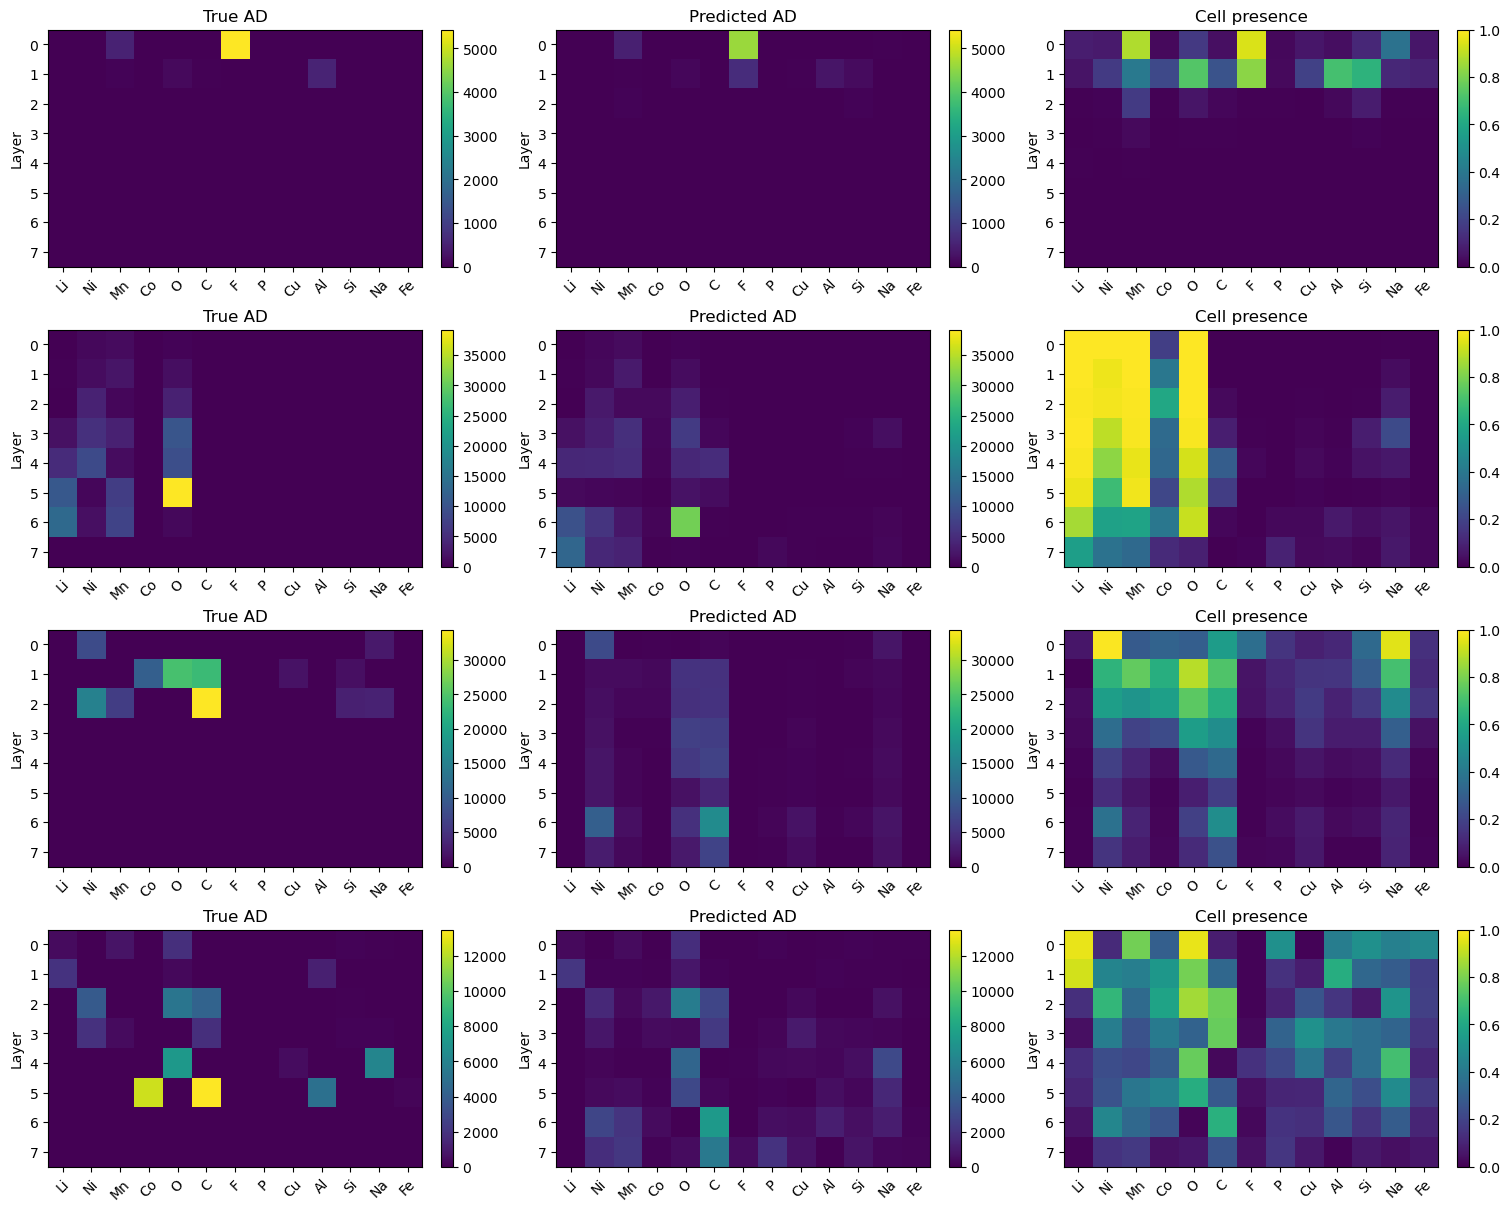

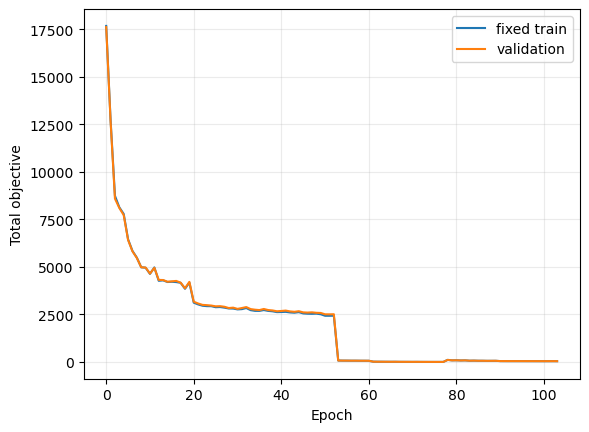

In [20]:
model.eval()
outputs, probabilities, conditional_stds, conditional_means = [], [], [], []
with torch.inference_mode():
    for start in range(0,len(x_test),BATCH_SIZE):
        prediction=model(torch.from_numpy(x_test[start:start+BATCH_SIZE]).to(device))
        outputs.append(prediction.mean.cpu().numpy())
        conditional_stds.append(prediction.E.cpu().numpy())
        conditional_means.append(prediction.Y.cpu().numpy())
        probabilities.append(prediction.P.cpu().numpy())
estimate=np.concatenate(outputs)/TARGET_SCALE
p=np.concatenate(probabilities)
truth=a_test/TARGET_SCALE
conditional_std=np.concatenate(conditional_stds)/TARGET_SCALE
present=truth>0
print('Test loss components:',evaluate_metrics(x_test,a_test,x_test_clean))
print('AD point-estimate MAE (1e15 atoms/cm2):',float(np.abs(estimate-truth).mean()))
print('Element inventory MAE (1e15 atoms/cm2):',float(np.abs(estimate.sum(1)-truth.sum(1)).mean()))
print('Presence Brier score:',float(np.square(p-present).mean()))
# Coverage is centered on conditional Y, not on the marginal posterior mean P*Y.
conditional_mean=np.concatenate(conditional_means)/TARGET_SCALE
print('Conditional Gaussian 95% coverage on true-present cells:',float((np.abs(truth[present]-conditional_mean[present])<=1.96*conditional_std[present]).mean()) if present.any() else 'no present cells')
fig,axes=plt.subplots(min(4,len(truth)),3,figsize=(15,3*min(4,len(truth))),squeeze=False,constrained_layout=True)
for i,row in enumerate(axes):
    common_max=max(float(truth[i].max()),float(estimate[i].max()),1e-6)
    displayed_presence=p[i]
    for axis,matrix,title in zip(row,(truth[i],estimate[i],displayed_presence),('True AD','Predicted AD','Cell presence')):
        im=axis.imshow(matrix,aspect='auto',vmin=0,vmax=1 if 'presence' in title else common_max)
        axis.set_xticks(range(len(ELEMENTS)),ELEMENTS,rotation=45);axis.set_ylabel('Layer');axis.set_title(title)
        fig.colorbar(im,ax=axis)
plt.show()
if history:
    losses=np.asarray(history);plt.plot(losses[:,0],label='fixed train');plt.plot(losses[:,1],label='validation')
    plt.xlabel('Epoch');plt.ylabel('Total objective');plt.legend();plt.grid(alpha=.25);plt.show()


## 6. Export and verify native inference

The version 4 package contains the reference sample/setup, detector channel
lengths, ordered elements, EDP dimensions and units. Its ONNX graph includes
log1p plus fitted normalization and outputs flattened **P × Y**. Package output
scaling restores physical units. It exports no hard existence threshold, so
small positive densities can remain in absent elements/layers.

Use the saved PyTorch checkpoint for conditional **Y, R** and sampling. A raw Gaussian
draw may be negative or have noncontiguous layers; project/filter it explicitly
before using it as a physical optimizer initialization. Such projection changes
the distribution from the draft. This notebook does not silently apply it.

The current datasets have pileup disabled. Export writes
`need_pileup_subtraction = true` in inverse metadata: external inference callers
can supply spectra and detector settings through `InverseInput` for automatic correction.
Already pileup-free spectra need no further subtraction.


The parity check uses `predict_prepared()` because dataset spectra already match
training conditions. For experiments, call `predict(InverseInput(...))`: the
library removes pileup, rebins, and scales exposure before the embedded transforms.
Set `pileup_already_removed=True` for spectra already corrected for pileup.

Native predictions also expose `presence_probability` and `posterior_std`, with the same layer/element shape as `values`. Standard deviation is in physical areal-density units and includes presence uncertainty.


In [21]:
package_path = OUTPUT_DIR / f"ibeamnet_{MAX_LAYERS}layers.zip"
export_suffix = 1
while package_path.exists():
    # A previous export may exist even if its parity check was interrupted.
    package_path = OUTPUT_DIR / f"ibeamnet_{MAX_LAYERS}layers_{export_suffix:03d}.zip"
    export_suffix += 1
# Verify against the same current CPU/eval weights used for ONNX export.
# `estimate` from section 5 may be stale or computed with CUDA kernels.
export_model = copy.deepcopy(model).cpu().eval()
check_count = min(8, len(x_test))
check_inputs = np.array(x_test[:check_count], dtype=np.float32, copy=True)
with torch.inference_mode():
    export_reference = torch.cat([
        export_model(torch.from_numpy(row[None])).mean
        for row in check_inputs], dim=0).numpy() / TARGET_SCALE
export_model.export(package_path, output_inverse_factor=TARGET_SCALE, need_pileup_subtraction=True,
             pileup_fudge_factor_seconds=0.4e-6)
metadata = native.model.ModelPackage.open(package_path).metadata
assert metadata.format_version == 4
assert metadata.class_name == "iBeamNet"
assert metadata.inverse.need_pileup_subtraction
np.testing.assert_allclose(metadata.inverse.pileup_fudge_factor_seconds, 0.4e-6)
assert list(metadata.inverse.output_edp.elements) == list(ELEMENTS)
assert metadata.inverse.output_edp.max_layers == MAX_LAYERS
assert metadata.input_transform.type == "identity"
np.testing.assert_allclose(metadata.output_transform.factor, TARGET_SCALE)

native_model = ibl.InverseModel(package_path)
measurements = []
for row in check_inputs:
    offset = 0
    item = {}
    for label in LABELS:
        width = SPECTRUM_LENGTHS[label]
        item[label] = ibl.Spectrum(label, row[offset:offset + width])
        offset += width
    measurements.append(item)
native_edp = np.stack([result.values for result in native_model.predict_prepared(measurements)])
max_export_difference = float(np.abs(native_edp - export_reference).max())
print(f"Native vs fresh CPU PyTorch maximum absolute difference: {max_export_difference:.6g}")
np.testing.assert_allclose(native_edp, export_reference, rtol=2e-4, atol=1e-3,
                           err_msg="Native export differs from current CPU/eval PyTorch predictions")
print("Verified native/PyTorch point-estimate parity:", package_path)

Native vs fresh CPU PyTorch maximum absolute difference: 0.0712891
Verified native/PyTorch point-estimate parity: D:\ibeamlab\examples\artifacts\ibeamnet_v4_gaussian_nll_13el_8layer\ibeamnet_8layers_002.zip
